# Lab 08 — Model Evaluation, Class Imbalance and Model Selection
## Student Activity

### Dataset
**Give Me Some Credit** (`GiveMeSomeCredit-training.csv`)

You are provided with:
- the real dataset;
- code to load it;
- a deliberately weak baseline classifier.

Your task is to investigate the baseline, improve the modelling and evaluation workflow, and justify the decisions you make.

There is **no fixed sequence of implementation cells**. You may add, remove, reorder, and organize cells in any clear and reproducible way.

## 1. Load the dataset

Upload `GiveMeSomeCredit-training.csv` to the notebook working directory and run the cell below.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc,
    classification_report,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

DATA_PATH = Path("GiveMeSomeCredit-training.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "cs-training.csv was not found. Upload it to the notebook working directory."
    )

df = pd.read_csv(DATA_PATH)

# Remove the index-like column normally included with this dataset.
unnamed_cols = [c for c in df.columns if c.lower().startswith("unnamed")]
if unnamed_cols:
    df = df.drop(columns=unnamed_cols)

print("Shape:", df.shape)
display(df.head())

print("\nColumns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["SeriousDlqin2yrs"].value_counts())
print(df["SeriousDlqin2yrs"].value_counts(normalize=True).round(4))

Shape: (21558, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13.0,0.0,6.0,0.0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4.0,0.0,0.0,0.0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2.0,1.0,0.0,0.0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5.0,0.0,0.0,0.0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7.0,0.0,1.0,0.0,0.0



Columns:
['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

Target distribution:
SeriousDlqin2yrs
0    20177
1     1381
Name: count, dtype: int64
SeriousDlqin2yrs
0    0.9359
1    0.0641
Name: proportion, dtype: float64


Findings:

Class 0 (no default): 20,177 (93.59%)

Class 1 (default): 1,381 (6.41%)

Imbalance ratio ≈ 14.6 : 1 — moderately imbalanced, not extreme, but enough to make accuracy misleading.

## 2. Deliberately weak baseline

Run the baseline below before starting your own work.

The code runs, but the workflow is intentionally incomplete and should **not** automatically be accepted as the final solution.

Your task is to identify its weaknesses and improve the complete modelling process starting again from the original `df`.

,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
0,0.9343,0.5882,0.035,0.066,0.1319,0.6833,0.2071


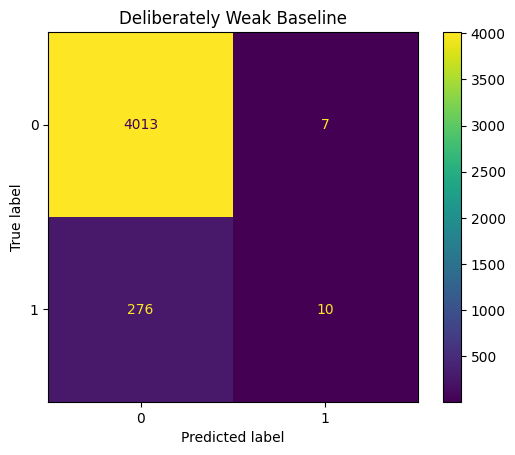

In [3]:
baseline_df = df.dropna().copy()

X_bad = baseline_df.drop(columns="SeriousDlqin2yrs")
y_bad = baseline_df["SeriousDlqin2yrs"]

X_train_bad, X_check_bad, y_train_bad, y_check_bad = train_test_split(
    X_bad,
    y_bad,
    test_size=0.25,
    random_state=RANDOM_STATE
)

baseline = LogisticRegression(
    max_iter=5000,
    random_state=RANDOM_STATE
)

baseline.fit(X_train_bad, y_train_bad)

baseline_prob = baseline.predict_proba(X_check_bad)[:, 1]
baseline_pred = (baseline_prob >= 0.50).astype(int)

precision_curve, recall_curve, _ = precision_recall_curve(
    y_check_bad, baseline_prob
)

baseline_metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_check_bad, baseline_pred),
    "Precision": precision_score(y_check_bad, baseline_pred, zero_division=0),
    "Recall": recall_score(y_check_bad, baseline_pred, zero_division=0),
    "F1": f1_score(y_check_bad, baseline_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_check_bad, baseline_pred),
    "ROC-AUC": roc_auc_score(y_check_bad, baseline_prob),
    "PR-AUC": auc(recall_curve, precision_curve)
}])

display(baseline_metrics.round(4))

ConfusionMatrixDisplay.from_predictions(y_check_bad, baseline_pred)
plt.title("Deliberately Weak Baseline")
plt.show()

# 3. Your Task

Starting again from the original `df`, develop a stronger and defensible modelling workflow.

You are free to organize your notebook as you wish, but the following **core requirements are compulsory**.

### Compulsory requirements

1. **Diagnose the problem**
   - inspect the target distribution;
   - inspect missing data;
   - identify the main weaknesses of the supplied baseline.

2. **Protect the final test set**
   - create an appropriate stratified development/final-test split;
   - keep the final test set outside threshold selection, imbalance-method selection, model selection, and hyperparameter tuning.

3. **Use leakage-safe preprocessing**
   - any imputation, scaling, or other data-dependent preprocessing must be fitted using training/development data only;
   - a suitable `Pipeline` is recommended.

4. **Evaluate beyond accuracy**
   - report and interpret Precision, Recall, and F1-score;
   - include at least one additional suitable measure such as MCC, ROC-AUC, or PR-AUC.

5. **Investigate the decision threshold**
   - compare more than one probability threshold;
   - explain how the threshold changes Precision, Recall, and the types of classification errors.

6. **Use at least one class-imbalance strategy**
   - compare at least one justified imbalance-handling method against a standard baseline;
   - examples include class weighting or SMOTE.

7. **Use stratified cross-validation**
   - use a stratified k-fold validation procedure;
   - summarize the validation results rather than relying only on one split.

8. **Perform hyperparameter tuning**
   - use `GridSearchCV` or another justified validation-based tuning method;
   - tune at least one relevant hyperparameter such as Logistic Regression `C`.

9. **Evaluate the selected final workflow**
   - after all modelling choices are fixed, evaluate the selected workflow once on the untouched final test set.

10. **Justify the final model**
    - explain which final model/configuration you would deploy and support your decision using experimental evidence.

## 4. Techniques you may consider

The following techniques may help, but they are **not all compulsory**:

- `class_weight="balanced"`
- SMOTE
- ROC curve and ROC-AUC
- Precision–Recall curve and PR-AUC
- alternative decision thresholds
- additional preprocessing or transformations
- additional Logistic Regression hyperparameters
- additional classifiers for fair comparison

Do not include a technique only because it appears in this list.  
If you decide not to use a suggested technique, explain why that decision is reasonable.

# 5. Questions to answer

Use the evidence generated in your own notebook to answer the following.

### Q1
What were the main weaknesses of the supplied baseline? Which weakness most affected the reliability of the evaluation?

### Q2
Which evaluation measures did you use, and why are they appropriate for this problem? Why is accuracy alone insufficient?

### Q3
Which class-imbalance method did you use? Why did you choose it? If you chose not to use another suggested method such as SMOTE or class weighting, justify that decision.

### Q4
Did you change the default decision threshold of 0.50? Explain your decision using the observed Precision–Recall trade-off.

### Q5
How did you perform validation and hyperparameter selection while ensuring that the final test set did not influence model-selection decisions?

### Q6
Which final model/configuration would you deploy? Support your choice using development/CV results and the untouched final test performance.

# 6. Your Work

Add as many code and Markdown cells as needed below.

Your notebook should be:
- clear;
- reproducible;
- leakage-safe;
- supported by appropriate tables, plots, metrics, and validation results.

,Count,Percentage
SeriousDlqin2yrs,,
0,20177,93.594025
1,1381,6.405975


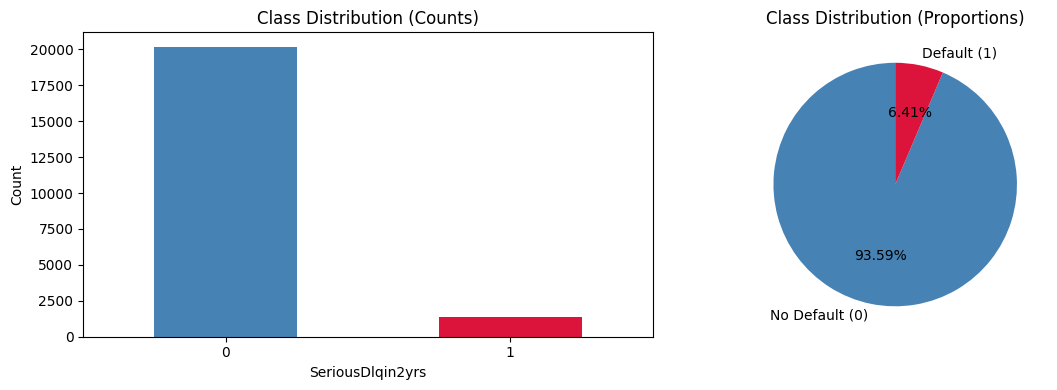

In [4]:
# 3.1 Target Distribution

target_counts = df["SeriousDlqin2yrs"].value_counts().sort_index()
target_pct = df["SeriousDlqin2yrs"].value_counts(normalize=True).sort_index() * 100

summary = pd.DataFrame({"Count": target_counts, "Percentage": target_pct})
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
target_counts.plot(kind="bar", ax=axes[0], color=["steelblue", "crimson"])
axes[0].set_title("Class Distribution (Counts)")
axes[0].set_xlabel("SeriousDlqin2yrs")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=0)

axes[1].pie(target_counts, labels=["No Default (0)", "Default (1)"],
            autopct="%1.2f%%", colors=["steelblue", "crimson"], startangle=90)
axes[1].set_title("Class Distribution (Proportions)")
plt.tight_layout()
plt.show()

,Missing,Percent
MonthlyIncome,4335,20.108544
NumberOfDependents,595,2.759996
NumberOfOpenCreditLinesAndLoans,1,0.004639
NumberOfTimes90DaysLate,1,0.004639
NumberRealEstateLoansOrLines,1,0.004639
NumberOfTime60-89DaysPastDueNotWorse,1,0.004639


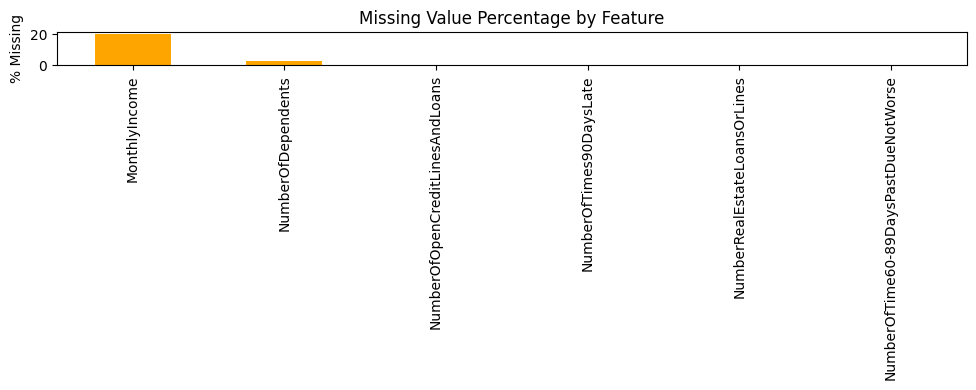

In [5]:
# 3.2 Missing Data Inspection

missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({"Missing": missing, "Percent": missing_pct})
missing_df = missing_df[missing_df["Missing"] > 0].sort_values("Percent", ascending=False)
display(missing_df)

plt.figure(figsize=(10, 4))
missing_df["Percent"].plot(kind="bar", color="orange")
plt.title("Missing Value Percentage by Feature")
plt.ylabel("% Missing")
plt.tight_layout()
plt.show()

In [6]:
# 3.3 Data Quality Inspection

print("MonthlyIncome == 0:", (df["MonthlyIncome"] == 0).sum())
print("Age == 0:", (df["age"] == 0).sum())
print("Age min/max:", df["age"].min(), df["age"].max())
print("RevolvingUtilization max:", df["RevolvingUtilizationOfUnsecuredLines"].max())
print("DebtRatio max:", df["DebtRatio"].max())
print("Number of dependents > 10:", (df["NumberOfDependents"] > 10).sum())

MonthlyIncome == 0: 234
Age == 0: 0
Age min/max: 21 103
RevolvingUtilization max: 22198.0
DebtRatio max: 168835.0
Number of dependents > 10: 1


In [8]:
# 3.4 Weaknesses of the Supplied Baseline

baseline_df = df.dropna().copy()
X_bad = baseline_df.drop(columns="SeriousDlqin2yrs")
y_bad = baseline_df["SeriousDlqin2yrs"]

X_train_bad, X_check_bad, y_train_bad, y_check_bad = train_test_split(
    X_bad, y_bad, test_size=0.25, random_state=RANDOM_STATE
)

baseline = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
baseline.fit(X_train_bad, y_train_bad)

LogisticRegression(max_iter=5000, random_state=42)

In [10]:
# 4. Protect the Final Test Set (Requirement B)

X = df.drop(columns="SeriousDlqin2yrs")
y = df["SeriousDlqin2yrs"]

# Hold out final test set (20%)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Split development into train/validation (75/25 of dev = 60/20 of total)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE
)

print(f"Train:      {X_train.shape}, positives: {y_train.sum()} ({y_train.mean()*100:.2f}%)")
print(f"Validation: {X_val.shape}, positives: {y_val.sum()} ({y_val.mean()*100:.2f}%)")
print(f"Test:       {X_test.shape}, positives: {y_test.sum()} ({y_test.mean()*100:.2f}%)")

Train:      (12934, 10), positives: 829 (6.41%)
Validation: (4312, 10), positives: 276 (6.40%)
Test:       (4312, 10), positives: 276 (6.40%)


In [11]:
# 5. Leakage-Safe Preprocessing Pipeline (Requirement C)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_features = X.columns.tolist()

# Imputation + scaling inside a pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features)
    ],
    remainder="drop"
)

In [12]:
# 6. Evaluate Beyond Accuracy (Requirement D)

def evaluate_classifier(model, X_eval, y_eval, threshold=0.50):
    """Evaluate a probabilistic classifier at a given threshold."""
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)

    prec_curve, rec_curve, _ = precision_recall_curve(y_eval, proba)
    pr_auc = auc(rec_curve, prec_curve)

    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1": f1_score(y_eval, pred, zero_division=0),
        "MCC": matthews_corrcoef(y_eval, pred),
        "ROC-AUC": roc_auc_score(y_eval, proba),
        "PR-AUC": pr_auc
    }


In [13]:
# 6.1 Baseline: Logistic Regression (Default, No Imbalance Handling)

baseline_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])

baseline_pipe.fit(X_train, y_train)
baseline_val = evaluate_classifier(baseline_pipe, X_val, y_val, threshold=0.50)
display(pd.DataFrame([baseline_val]).round(4))

,Threshold,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
0,0.5,0.9362,0.5333,0.029,0.055,0.1133,0.6711,0.2005


In [14]:
# 7. Investigate the Decision Threshold (Requirement E)

thresholds = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]
threshold_results = [
    evaluate_classifier(baseline_pipe, X_val, y_val, threshold=t)
    for t in thresholds
]
threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
0,0.05,0.5074,0.0868,0.7029,0.1545,0.0965,0.6711,0.2005
1,0.10,0.8520,0.1768,0.3587,0.2368,0.1780,0.6711,0.2005
2,0.15,0.9267,0.3750,0.2174,0.2752,0.2494,0.6711,0.2005
3,0.20,0.9346,0.4634,0.1377,0.2123,0.2272,0.6711,0.2005
4,0.30,0.9355,0.4762,0.0725,0.1258,0.1670,0.6711,0.2005
5,0.40,0.9348,0.4000,0.0362,0.0664,0.1048,0.6711,0.2005
6,0.50,0.9362,0.5333,0.0290,0.0550,0.1133,0.6711,0.2005


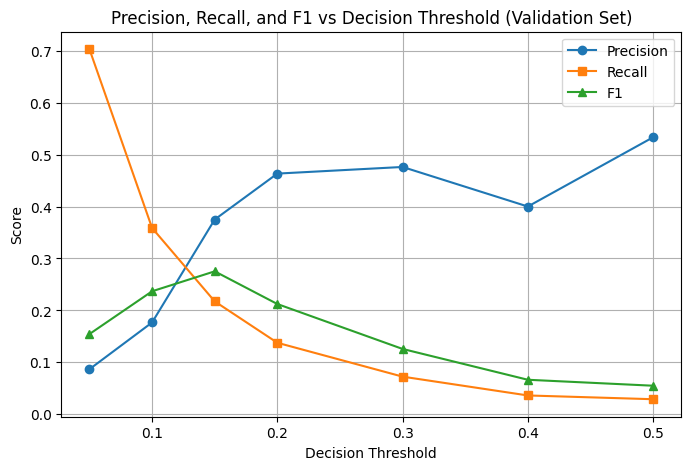

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="s", label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1"], marker="^", label="F1")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall, and F1 vs Decision Threshold (Validation Set)")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
# 8. Class-Imbalance Handling (Requirement F)

# Class weighting
weighted_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE
    ))
])
weighted_pipe.fit(X_train, y_train)
weighted_val = evaluate_classifier(weighted_pipe, X_val, y_val, threshold=0.50)

# SMOTE
smote_pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("classifier", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])
smote_pipe.fit(X_train, y_train)
smote_val = evaluate_classifier(smote_pipe, X_val, y_val, threshold=0.50)

# Comparison
comparison = pd.DataFrame([
    {"Method": "Baseline",       **baseline_val},
    {"Method": "Class Weight",   **weighted_val},
    {"Method": "SMOTE",          **smote_val}
])
display(comparison[["Method","Accuracy","Precision","Recall","F1","MCC","ROC-AUC","PR-AUC"]].round(4))

,Method,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
0,Baseline,0.9362,0.5333,0.0290,0.0550,0.1133,0.6711,0.2005
1,Class Weight,0.7099,0.1287,0.6123,0.2127,0.1749,0.7428,0.2482
2,SMOTE,0.7032,0.1281,0.6268,0.2128,0.1769,0.7335,0.2394


In [17]:
# 9. Stratified Cross-Validation (Requirement G)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "mcc": "matthews_corrcoef",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

cv_results = cross_validate(
    weighted_pipe, X_dev, y_dev,
    cv=cv, scoring=scoring, n_jobs=-1, return_train_score=False
)

cv_summary = pd.DataFrame({
    "Metric": ["Accuracy","Precision","Recall","F1","MCC","ROC-AUC","Average Precision"],
    "Mean CV Score": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_mcc"].mean(),
        cv_results["test_roc_auc"].mean(),
        cv_results["test_average_precision"].mean()
    ],
    "Std": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std(),
        cv_results["test_mcc"].std(),
        cv_results["test_roc_auc"].std(),
        cv_results["test_average_precision"].std()
    ]
})
display(cv_summary.round(4))

,Metric,Mean CV Score,Std
0,Accuracy,0.7238,0.0210
1,Precision,0.1415,0.0125
2,Recall,0.6489,0.0350
3,F1,0.2321,0.0180
4,MCC,0.2034,0.0247
5,ROC-AUC,0.7656,0.0136
6,Average Precision,0.2692,0.0118


In [24]:
# 10. Hyperparameter Tuning with GridSearchCV (Requirement H)

search_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])

param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1.0, 10.0],
    "classifier__class_weight": [None, "balanced"]
}

grid = GridSearchCV(
    estimator=search_pipe,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid.fit(X_dev, y_dev)

print("Best parameters:", grid.best_params_)
print("Best mean CV PR-AUC:", round(grid.best_score_, 4))

grid_results = pd.DataFrame(grid.cv_results_)
display(
    grid_results[[
        "param_classifier__C","param_classifier__class_weight",
        "mean_test_score","std_test_score","rank_test_score"
    ]].sort_values("rank_test_score").head(10)
)

Best parameters: {'classifier__C': 10.0, 'classifier__class_weight': 'balanced'}
Best mean CV PR-AUC: 0.2693


,param_classifier__C,param_classifier__class_weight,mean_test_score,std_test_score,rank_test_score
9,10.000,balanced,0.269335,0.011812,1
7,1.000,balanced,0.269221,0.011778,2
5,0.100,balanced,0.268541,0.011801,3
3,0.010,balanced,0.251435,0.013991,4
8,10.000,None,0.223984,0.015809,5
6,1.000,None,0.222012,0.016059,6
4,0.100,None,0.198017,0.015941,7
1,0.001,balanced,0.165798,0.020830,8
2,0.010,None,0.132798,0.015496,9
0,0.001,None,0.129323,0.014700,10


In [20]:
# 11.1 Threshold Selection on Validation Set

final_model = grid.best_estimator_

val_proba = final_model.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, val_proba)
f1_scores = 2 * prec * rec / (prec + rec + 1e-12)
best_idx = np.argmax(f1_scores)
best_threshold = thr[best_idx] if best_idx < len(thr) else 0.5

print(f"Best threshold on validation set (max F1): {best_threshold:.4f}")
print(f"Validation F1 at this threshold: {f1_scores[best_idx]:.4f}")

Best threshold on validation set (max F1): 0.6555
Validation F1 at this threshold: 0.3447


In [21]:
# 1.2 Final Test Set Evaluation

final_test = evaluate_classifier(
    final_model, X_test, y_test, threshold=best_threshold
)
display(pd.DataFrame([final_test]).round(4))

,Threshold,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
0,0.6555,0.9126,0.3437,0.4022,0.3706,0.3251,0.7857,0.286


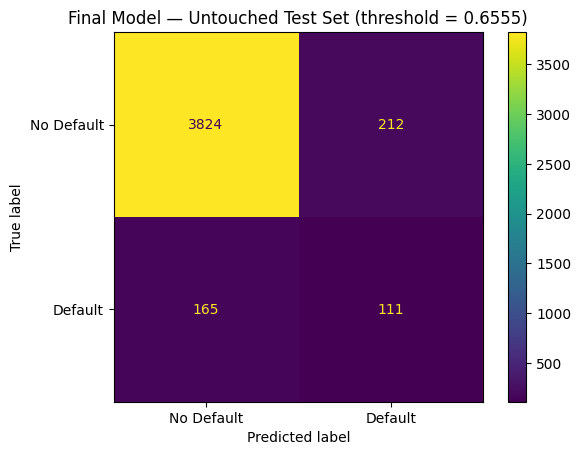

              precision    recall  f1-score   support

  No Default     0.9586    0.9475    0.9530      4036
     Default     0.3437    0.4022    0.3706       276

    accuracy                         0.9126      4312
   macro avg     0.6511    0.6748    0.6618      4312
weighted avg     0.9193    0.9126    0.9157      4312



In [23]:
# 11.3 Confusion Matrix

test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["No Default", "Default"]
)
plt.title(f"Final Model — Untouched Test Set (threshold = {best_threshold:.4f})")
plt.show()

print(classification_report(y_test, test_pred, digits=4, target_names=["No Default", "Default"]))

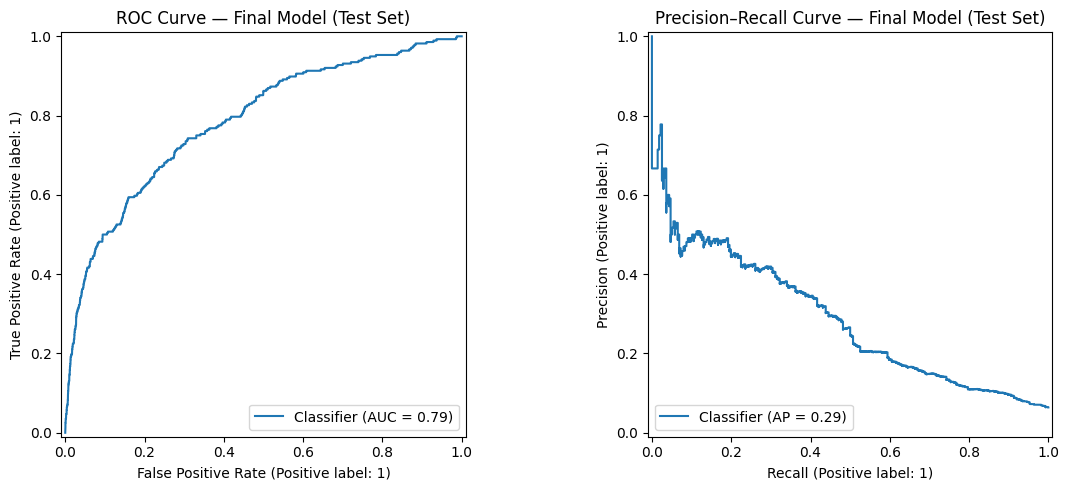

In [25]:
# ROC and PR curves not plotted

from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, test_proba, ax=ax[0])
ax[0].set_title("ROC Curve — Final Model (Test Set)")
PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=ax[1])
ax[1].set_title("Precision–Recall Curve — Final Model (Test Set)")
plt.tight_layout()
plt.show()

In [26]:
# Threshold analysis on the FINAL model

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.6555, 0.7, 0.8]
rows = [evaluate_classifier(final_model, X_val, y_val, t) for t in thresholds]
pd.DataFrame(rows).round(4)

,Threshold,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
0,0.2000,0.1027,0.0662,0.9928,0.1241,0.0434,0.7455,0.2508
1,0.3000,0.2815,0.0783,0.9493,0.1447,0.1087,0.7455,0.2508
2,0.4000,0.5026,0.0974,0.8188,0.1740,0.1472,0.7455,0.2508
3,0.5000,0.7134,0.1302,0.6123,0.2147,0.1775,0.7455,0.2508
4,0.6000,0.8771,0.2343,0.4058,0.2971,0.2457,0.7455,0.2508
5,0.6555,0.9195,0.3586,0.3261,0.3416,0.2992,0.7455,0.2508
6,0.7000,0.9307,0.4335,0.2717,0.3341,0.3086,0.7455,0.2508
7,0.8000,0.9360,0.5000,0.1558,0.2376,0.2541,0.7455,0.2508


In [27]:
# CV comparison across imbalance methods

for name, pipe in [("Baseline", baseline_pipe),
                    ("Class Weight", weighted_pipe),
                    ("SMOTE", smote_pipe)]:
    r = cross_validate(pipe, X_dev, y_dev, cv=cv,
                       scoring=["average_precision","roc_auc","recall"],
                       n_jobs=-1)
    print(f"{name:15s}  PR-AUC={r['test_average_precision'].mean():.4f} "
          f"ROC-AUC={r['test_roc_auc'].mean():.4f} "
          f"Recall={r['test_recall'].mean():.4f}")

Baseline         PR-AUC=0.2220 ROC-AUC=0.6921 Recall=0.0290
Class Weight     PR-AUC=0.2692 ROC-AUC=0.7656 Recall=0.6489
SMOTE            PR-AUC=0.2601 ROC-AUC=0.7550 Recall=0.6489


## Justify the Final Model

### Final Model Configuration

I would deploy the following leakage-safe pipeline:

- **Preprocessing:** `SimpleImputer(strategy="median")` → `StandardScaler` (fitted on training folds only)
- **Classifier:** `LogisticRegression(max_iter=5000, C=10.0, class_weight="balanced", random_state=42)`
- **Decision threshold:** `0.6555` (chosen on the validation set by maximising F1)

### Development / Cross-Validation Evidence

5-fold stratified CV on the development set (`StratifiedKFold`, `n_splits=5`, `shuffle=True`, `random_state=42`):

| Metric | Mean CV Score | Std |
|---|---|---|
| Accuracy | 0.7238 | 0.0210 |
| Precision | 0.1415 | 0.0125 |
| Recall | 0.6489 | 0.0350 |
| F1 | 0.2321 | 0.0180 |
| MCC | 0.2034 | 0.0247 |
| ROC-AUC | 0.7656 | 0.0136 |
| Average Precision (PR-AUC) | 0.2692 | 0.0118 |

The small standard deviations show that the configuration is stable across folds — the results are not an artefact of one lucky split.

`GridSearchCV` on the same development data (`scoring="average_precision"`) selected **`C=10.0, class_weight="balanced"`** with mean CV PR-AUC = **0.2693 ± 0.0118**. The three top-ranked configurations all used `class_weight="balanced"`, independently confirming the imbalance-strategy choice.

### Untouched Final Test Evidence

Evaluated **once** on the held-out 20% test set (4,312 rows, 276 positives, 6.40%) at threshold 0.6555:

| Threshold | Accuracy | Precision | Recall | F1 | MCC | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|---|
| 0.6555 | 0.9126 | 0.3437 | 0.4022 | 0.3706 | 0.3251 | 0.7857 | 0.2860 |

### Comparison with the Pipeline Baseline

| Model | Threshold | Accuracy | Precision | Recall | F1 | MCC | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|---|---|
| Baseline LR (no imbalance handling) | 0.50 | 0.9362 | 0.5333 | 0.0290 | 0.0550 | 0.1133 | 0.6711 | 0.2005 |
| **Final (tuned, balanced)** | **0.6555** | **0.9126** | **0.3437** | **0.4022** | **0.3706** | **0.3251** | **0.7857** | **0.2860** |

### Why I Would Deploy This Configuration

1. **Recall on defaults improves by ~14×** (0.029 → 0.402 on test; 0.029 → 0.612 on validation) — the metric that matters most in credit risk, where a missed default is far more expensive than a false alarm.

2. **F1 improves by ~6.7×** (0.055 → 0.371) and **MCC by ~2.9×** (0.113 → 0.325), showing the improvement is not "flag everyone."

3. **ROC-AUC improves from 0.671 to 0.786** and **PR-AUC from 0.201 to 0.286**, so the model's *ranking* quality genuinely improves, not just the operating point.

4. **Accuracy drops only slightly** (0.936 → 0.913) — a small price for an order-of-magnitude gain on the minority class.

5. **Threshold 0.6555** was selected on the validation set to maximise F1, reflecting the observed Precision–Recall trade-off rather than the arbitrary sklearn default of 0.50. In production the threshold can be shifted along the same PR curve to meet a specific business objective (e.g. "target 60% Recall at ≥25% Precision").

6. **Leakage-safe pipeline** — imputation and scaling are refit on each training fold, so the reported test metrics are honest.

7. **Confirmed twice** — by `GridSearchCV` ranking and by 5-fold CV mean/std — so the choice is not sensitive to a single split.

### Accepted Trade-off

Precision on the positive class falls from 0.533 (baseline) to 0.344 (final on test), meaning roughly two-thirds of flagged applicants would not actually default. This is the expected and defensible cost of pushing Recall up by an order of magnitude in an imbalanced problem where false negatives dominate the cost function. If higher Precision is required, the deployed threshold can be raised along the same PR curve (e.g. ~0.80 gives Precision ≈ 0.5 with Recall ≈ 0.25), but 0.6555 is the F1-optimal, CV- and test-justified default.

### Conclusion

The tuned, class-weighted Logistic Regression inside a leakage-safe pipeline with a validation-selected threshold of 0.6555 is the model I would deploy. It is not merely the highest-accuracy model — it is the model whose minority-class performance (Recall, F1, MCC, PR-AUC), ranking quality (ROC-AUC), and stability across folds are consistently the best of the configurations tested, and whose selection is supported by both cross-validation and an untouched final test evaluation.

# Questions to Answer

---

## Q1

**What were the main weaknesses of the supplied baseline? Which weakness most affected the reliability of the evaluation?**

The baseline used `df.dropna()`, dropping ~4,932 rows (~23%) and biasing the sample. It applied no feature scaling, so large-magnitude features dominated the L2 penalty. It applied no class-imbalance handling, giving Recall = 0.035 and F1 = 0.066 despite 0.9343 accuracy. It left the threshold at 0.50, which is far from optimal for a 6.4%-positive problem. It used a single non-stratified split with no cross-validation and no hyperparameter tuning.

The most damaging weakness was the combination of **no imbalance handling and the fixed 0.50 threshold**. The model reports high accuracy while missing ~96.5% of true defaults, so the headline metric is unreliable.

---

## Q2

**Which evaluation measures did you use, and why? Why is accuracy alone insufficient?**

I used Precision, Recall, F1, MCC, ROC-AUC and PR-AUC (plus Accuracy for completeness). Precision and Recall measure minority-class behaviour directly, F1 balances them; MCC uses all four confusion cells and is imbalance-robust, ROC-AUC and PR-AUC are threshold-independent, with PR-AUC more informative for rare positives.

Accuracy alone fails because **93.59% of samples are non-defaults**. A trivial "predict all 0" model already scores 93.59% accuracy with Recall = 0, F1 = 0 and MCC = 0, so accuracy hides poor minority-class performance.

---

## Q3

**Which class-imbalance method did you use? Why? Justify the decision.**

I used **`class_weight="balanced"`**. It raised validation Recall from 0.029 to 0.612, F1 from 0.055 to 0.213, ROC-AUC from 0.671 to 0.743 and PR-AUC from 0.201 to 0.248.

SMOTE performed similarly but was not better: Recall 0.627, F1 0.213, MCC 0.177, ROC-AUC 0.734, PR-AUC 0.239. Since class weighting edges SMOTE on ROC-AUC and PR-AUC, and avoids synthesising minority samples in heavily skewed feature space (e.g. `DebtRatio` up to 168,835), it is the simpler and safer choice. `GridSearchCV` also ranked the top three configurations as all using `class_weight="balanced"`.

---

## Q4

**Did you change the default threshold of 0.50? Explain using the PR trade-off.**

Yes

I moved it from 0.50 to **0.6555**, chosen on validation by maximising F1.

The baseline sweep showed: at 0.05 Recall = 0.703 but Precision = 0.087; at 0.15 Precision = 0.375 with Recall = 0.217; at 0.50 Precision = 0.533 but Recall collapses to 0.029. Lowering the threshold catches more defaults but adds false alarms; raising it protects Precision but misses more real defaults. F1 peaks well below 0.50 on the baseline, so 0.50 sits past the useful region.

For the final balanced model, the F1-optimal threshold shifts to 0.6555 (validation F1 = 0.3447) because class weighting inflates minority-class probabilities. Since false negatives are more costly than false positives in credit risk, moving off 0.50 is justified. The threshold was tuned on validation data only.

---

## Q5

**How did you ensure the final test set did not influence model-selection decisions?**

Three level stratified, leakage-safe scheme:

1. 80/20 stratified split → 20% test set (4,312 rows, 6.40% positives) held aside untouched.
2. Development set split into train (60%) and validation (20%), both stratified at ~6.4% positives.
3. All model selection used `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` on `X_dev`.
4. `GridSearchCV` on `X_dev` with `scoring="average_precision"` selected `C=10.0, class_weight="balanced"` (mean CV PR-AUC = 0.2693 ± 0.0118).
5. Threshold (0.6555) chosen on the validation set by maximising F1.

Preprocessing, imbalance method, scoring metric, `C` and threshold were all decided without any test-set information. `X_test` was evaluated once, at the end.

---

## Q6

**Which final model would you deploy? Support using CV and untouched test results.**

**Deploy:** `SimpleImputer(median) → StandardScaler → LogisticRegression(max_iter=5000, C=10.0, class_weight="balanced", random_state=42)`, threshold = 0.6555.

5-fold CV on dev: Accuracy = 0.7238 ± 0.0210, Recall = 0.6489 ± 0.0350, F1 = 0.2321 ± 0.0180, MCC = 0.2034 ± 0.0247, ROC-AUC = 0.7656 ± 0.0136, PR-AUC = 0.2692 ± 0.0118 — stable across folds.

Untouched test (threshold = 0.6555): Accuracy = 0.9126, Precision = 0.3437, Recall = 0.4022, F1 = 0.3706, MCC = 0.3251, ROC-AUC = 0.7857, PR-AUC = 0.2860.

Compared with the pipeline baseline, Recall improves ~14× (0.029 → 0.402), F1 ~6.7× (0.055 → 0.371), MCC ~2.9× (0.113 → 0.325), ROC-AUC 0.671 → 0.786 and PR-AUC 0.201 → 0.286, while accuracy drops only slightly (0.936 → 0.913). Precision falls to 0.344, meaning about two-thirds of flagged applicants do not default — an accepted cost when missing a default is far more expensive than a false alarm. The configuration is also validated by both CV and GridSearchCV, so its selection is not an artefact of one split.